#Aprendizaje supervisado

Implemente el modelo de árbol de decisión (mandatorio). Puede comparar opcionalmente con regresión logística.

# 1. Carga de datos
En esta primera sección, realizamos la carga del dataset directamente desde el almacenamiento de sesión de Colab. Utilizaremos la librería Pandas para leer el archivo y estructurar la información en forma de tabla para su posterior análisis.

**Nota técnica:** Para que el código se ejecute correctamente, es necesario subir previamente el archivo df_restaurante.csv de forma manual al panel de archivos del entorno.



In [ ]:
import pandas as pd

#  Definimos el nombre exacto del archivo que subimos
ruta_archivo = 'df_restaurante.csv'

#  Cargamos el archivo en la variable 'datos'
datos = pd.read_csv(ruta_archivo)

#  Confirmamos que todo está en orden
datos.head()


,TipoComida,Clientes,Hambriento,Precio,TiempoEspera,Rating,Esperar
0,Italiana,Ninguno,No,Alto,30+,Bueno,1
1,Burger,Ninguno,Sí,Bajo,30+,Bueno,1
2,Italiana,Lleno,Sí,Medio,0-10,Regular,0
3,Italiana,Lleno,Sí,Medio,0-10,Regular,1
4,Italiana,Ninguno,No,Alto,30+,Regular,0


#2. Exploración Inicial
Antes de procesar la data, realizamos una inspección técnica para conocer la cantidad de registros, si existen valores vacíos y el tipo de dato de cada columna.



In [ ]:
print("--- DIAGNÓSTICO TÉCNICO ---")
# Esto nos dirá si hay datos nulos y el tipo de dato
datos.info()

print("\n" + "="*40)
print("INSPECCIÓN DE CATEGORÍAS POR COLUMNA")
print("="*40)

# Este bucle recorre las columnas y nos muestra qué opciones hay en cada una
for col in datos.columns:
    print(f"-> {col:15}: {datos[col].unique()}")

--- DIAGNÓSTICO TÉCNICO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   TipoComida    1000 non-null   object
 1   Clientes      1000 non-null   object
 2   Hambriento    1000 non-null   object
 3   Precio        1000 non-null   object
 4   TiempoEspera  1000 non-null   object
 5   Rating        1000 non-null   object
 6   Esperar       1000 non-null   int64 
dtypes: int64(1), object(6)
memory usage: 54.8+ KB

INSPECCIÓN DE CATEGORÍAS POR COLUMNA
-> TipoComida     : ['Italiana' 'Burger' 'Francesa' 'Thailandesa']
-> Clientes       : ['Ninguno' 'Lleno' 'Algunos']
-> Hambriento     : ['No' 'Sí']
-> Precio         : ['Alto' 'Bajo' 'Medio']
-> TiempoEspera   : ['30+' '0-10' '10-30']
-> Rating         : ['Bueno' 'Regular' 'Malo']
-> Esperar        : [1 0]


##2.1 Hallazgos del Diagnóstico
Contamos con 1000 filas, lo que permite tener una base de aprendizaje sólida
para el modelo.

El dataset no presenta valores nulos (vacíos), por lo que la información está completa.

Se observa que las variables predictoras son de tipo object (texto). Esto es un hallazgo crítico, ya que los modelos de inteligencia artificial requieren valores numéricos para sus cálculos. Por lo tanto, será obligatorio realizar una transformación (Encoding) en la siguiente fase.



# 3. Definición de X e y (separar variables)
## He realizado la división del dataset en dos grupos para que el modelo pueda aprender correctamente:

**La Variable Objetivo (y) es la columna Esperar:**
Es la columna más importante porque es la respuesta final. La elegimos como y porque es lo que queremos que la Inteligencia Artificial aprenda a adivinar. Es el "Sí" o el "No" que decidió el cliente después de ver cómo estaba el restaurante.

**Las Variables Predictoras (X) :**
Son todas las demás (Tipo de comida, Precio, Hambre, etc.). Las elegimos como X porque son las pistas o motivos. Para que la IA pueda adivinar si alguien va a esperar, primero necesita saber el contexto: si el lugar es caro, si está lleno o si el cliente tiene mucha hambre.


In [ ]:
#  Asignamos a 'X' las características de entrada (quitando la respuesta)
X = datos.drop(columns=['Esperar'])

#  Asignamos a 'y' la respuesta que queremos predecir
y = datos['Esperar']

#   Verificación de la estructura
print(f"Dataset X (Entradas) : {X.shape[1]} columnas")
print(f"Variable y (Salida)   : {y.name}")
print("-" * 40)

#  Visualización de los datos preparados para el siguiente paso
X.head(3)

Dataset X (Entradas) : 6 columnas
Variable y (Salida)   : Esperar
----------------------------------------


,TipoComida,Clientes,Hambriento,Precio,TiempoEspera,Rating
0,Italiana,Ninguno,No,Alto,30+,Bueno
1,Burger,Ninguno,Sí,Bajo,30+,Bueno
2,Italiana,Lleno,Sí,Medio,0-10,Regular


#¿Para qué sirve este paso?
Si dejamos la respuesta dentro de las preguntas, el modelo "haría trampa" y no aprendería a razonar. Al separarlas, obligamos al algoritmo a buscar patrones en las pistas ($X$) para intentar adivinar la meta ($y$).

Aunque los datos ya están separados, la mayoría son texto (como "Italiana" o "Alto"). Como el Árbol de Decisión funciona con cálculos matemáticos, la siguiente fase abordara este problema ya que se encargaria del Preprocesamiento para convertir esas palabras en números (Encoding) y así poder entrenar el modelo.

##3.1. Diccionario de Datos
En esta sección documento el significado de cada columna analizada en los 1000 registros:

**TipoComida:**  Define el estilo de cocina (Italiana, Burger, Francesa o Thailandesa). Es una variable categórica.

**Clientes:** Indica la ocupación del local (Ninguno, Algunos o Lleno). Es clave para la decisión final.

**Hambriento:** Variable binaria que indica si el cliente tiene urgencia por comer.

**Precio:** Clasifica el costo del menú en tres niveles (Alto, Medio o Bajo).

**TiempoEspera:** Es el tiempo estimado comunicado (0-10, 10-30 o 30+ minutos).

**Rating:** Calificación de la calidad del servicio (Malo, Regular o Bueno).

**Esperar (Variable y):** Es nuestra meta. Indica si el cliente decidió quedarse (1) o irse (0).


##3.2. Análisis de Posibles Problemas


In [ ]:
#  Verificación de duplicados
print(f"Registros duplicados encontrados: {datos.duplicated().sum()}")


# Verificamos el balance de la meta para ver si los datos están sesgados
print("--- BALANCE DE LA VARIABLE OBJETIVO (y) ---")
print(y.value_counts(normalize=True) * 100)

print("\n" + "="*40)
# Contamos categorías para prever la complejidad del árbol
print("--- CANTIDAD DE CATEGORÍAS POR PISTA ---")
for col in X.columns:
                 print(f"{col:15}: {X[col].nunique()} opciones")

print("\n" + "="*40)
#  REPRESENTACIÓN DETALLADA (Frecuencias por cada opción)

print("--- DISTRIBUCIÓN DE CADA CATEGORÍA ---")
for col in X.columns:
    print(f"\nFrecuencia en {col}:")
    print(X[col].value_counts())


Registros duplicados encontrados: 545
--- BALANCE DE LA VARIABLE OBJETIVO (y) ---
Esperar
1    50.2
0    49.8
Name: proportion, dtype: float64

--- CANTIDAD DE CATEGORÍAS POR PISTA ---
TipoComida     : 4 opciones
Clientes       : 3 opciones
Hambriento     : 2 opciones
Precio         : 3 opciones
TiempoEspera   : 3 opciones
Rating         : 3 opciones

--- DISTRIBUCIÓN DE CADA CATEGORÍA ---

Frecuencia en TipoComida:
TipoComida
Italiana       250
Burger         250
Francesa       250
Thailandesa    250
Name: count, dtype: int64

Frecuencia en Clientes:
Clientes
Lleno      334
Ninguno    333
Algunos    333
Name: count, dtype: int64

Frecuencia en Hambriento:
Hambriento
No    500
Sí    500
Name: count, dtype: int64

Frecuencia en Precio:
Precio
Alto     334
Bajo     333
Medio    333
Name: count, dtype: int64

Frecuencia en TiempoEspera:
TiempoEspera
30+      334
0-10     334
10-30    332
Name: count, dtype: int64

Frecuencia en Rating:
Rating
Bueno      334
Regular    333
Malo       333
N

##3.3. Análisis final de preparación

**He concluido la fase de exploración y estas son mis conclusiones técnicas sobre los 1000 registros analizados:**

**Identificación de Roles:** He definido que la variable objetivo (**Y**) sea Esperar porque es la meta que queremos predecir. Las otras 6 columnas las he asignado como variables predictoras (**X**) porque son las pistas necesarias para que el modelo aprenda.

**Análisis de Duplicados:** Dado que el número de combinaciones posibles de atributos es limitado y el dataset tiene 1000 registros, la presencia de duplicados era esperable. Estos duplicados no necesariamente representan un error, pero deben interpretarse con cuidado, ya que pueden reforzar patrones frecuentes o también evidenciar combinaciones repetidas con resultados distintos en la variable objetivo.

**Calidad de la Data:** He verificado que el dataset está completo al 100%. No existen valores nulos, lo que nos da una base de entrenamiento sólida y sin "huecos".

**Análisis de Balance:** Tras ejecutar la prueba de distribución, he detectado que la meta está equilibrada (50.2% vs 49.8%). Esto es ideal porque el modelo aprenderá de igual manera a predecir tanto el "Sí" como el "No".

**Complejidad de las Pistas:** He identificado que nuestras variables tienen entre 2, 3 y 4 opciones (como el tipo de comida). Es importante notar esto porque estas opciones definirán cuántas ramas tendrá nuestro Árbol de Decisión; al tener pocas categorías, el modelo será más eficiente y fácil de interpretar.

**Distribución Uniforme de Pistas (X):** Tras revisar las frecuencias, he confirmado que la data es extremadamente equitativa. Por ejemplo:

TipoComida: Cada una de las 4 opciones tiene exactamente 250 registros.

Hambriento: Está dividido exactamente en 500 "Sí" y 500 "No".

Clientes, Precio y Rating: Todas las opciones tienen una representación casi idéntica (entre 332 y 334 registros).

**Problemas detectados:** El principal reto técnico que he identificado es que las 6 variables en **X** son de tipo texto (object). Como los algoritmos de Árbol de Decisión trabajan con lógica matemática, no pueden procesar estas palabras directamente.


In [ ]:
# 1. Columnas de entrada
columnas_X = X.columns.tolist()

# 2. Buscar combinaciones de X con más de una clase en y
conflictos = (
    datos.groupby(columnas_X)['Esperar']
    .nunique()
    .reset_index(name='n_clases')
)

conflictos = conflictos[conflictos['n_clases'] > 1]

print("¿Hay combinaciones iguales de X con diferente y?:", len(conflictos) > 0)
print("Cantidad de combinaciones conflictivas:", len(conflictos))

# 3. Unir esas combinaciones con el dataset original para ver el conflicto real
conflictos_detalle = datos.merge(conflictos[columnas_X], on=columnas_X, how='inner')

# 4. Ordenar para verlo mejor
conflictos_detalle = conflictos_detalle.sort_values(columnas_X + ['Esperar'])

conflictos_detalle.head(20)

¿Hay combinaciones iguales de X con diferente y?: True
Cantidad de combinaciones conflictivas: 73


,TipoComida,Clientes,Hambriento,Precio,TiempoEspera,Rating,Esperar
89,Burger,Algunos,No,Bajo,0-10,Malo,0
92,Burger,Algunos,No,Bajo,0-10,Malo,1
190,Burger,Algunos,No,Medio,10-30,Regular,0
196,Burger,Algunos,No,Medio,10-30,Regular,0
214,Burger,Algunos,No,Medio,10-30,Regular,0
158,Burger,Algunos,No,Medio,10-30,Regular,1
125,Burger,Algunos,Sí,Bajo,0-10,Malo,0
162,Burger,Algunos,Sí,Bajo,0-10,Malo,0
192,Burger,Algunos,Sí,Bajo,0-10,Malo,0
118,Burger,Algunos,Sí,Bajo,0-10,Malo,1


##3.4 Verificación de combinaciones conflictivas
Se agrega esta verificación para identificar si existen combinaciones iguales de variables predictoras asociadas a diferentes valores de la variable objetivo Esperar. Esto permite detectar ambigüedad en el dataset y comprender mejor si el problema presenta casos donde las mismas condiciones del restaurante no conducen siempre a la misma respuesta.

In [ ]:
# Verificar si hay combinaciones iguales de X con diferente y
columnas_X = X.columns.tolist()

conflictos = (
    datos.groupby(columnas_X)['Esperar']
    .nunique()
    .reset_index(name='n_clases')
)

conflictos = conflictos[conflictos['n_clases'] > 1]

print("¿Hay combinaciones iguales de X con diferente y?:", len(conflictos) > 0)
print("Cantidad de combinaciones conflictivas:", len(conflictos))

¿Hay combinaciones iguales de X con diferente y?: True
Cantidad de combinaciones conflictivas: 73


El resultado muestra que sí existen combinaciones iguales de variables predictoras con distinta salida en Esperar. Esto sugiere que el problema no es completamente determinista y que el modelo deberá aprender patrones con cierto nivel de incertidumbre.

## 4. Preprocesamiento (convertir variables categóricas)

###4.1 Codificacion de variables categoricas
Las variables predictoras del dataset son categóricas, por lo que deben transformarse a formato numérico antes de entrenar el modelo. Para ello se aplicó One-Hot Encoding mediante pd.get_dummies(), ya que este método crea una columna binaria por cada categoría y evita imponer un orden artificial entre valores categóricos. Se usa dtype=int para representar las columnas codificadas con valores 0 y 1.

In [ ]:
# Codificación One-Hot de las variables categóricas
X_encoded = pd.get_dummies(X, drop_first=False, dtype=int)

print("Dimensiones de X antes del encoding:", X.shape)
print("Dimensiones de X después del encoding:", X_encoded.shape)
X_encoded.head()

Dimensiones de X antes del encoding: (1000, 6)
Dimensiones de X después del encoding: (1000, 18)


,TipoComida_Burger,TipoComida_Francesa,TipoComida_Italiana,TipoComida_Thailandesa,Clientes_Algunos,Clientes_Lleno,Clientes_Ninguno,Hambriento_No,Hambriento_Sí,Precio_Alto,Precio_Bajo,Precio_Medio,TiempoEspera_0-10,TiempoEspera_10-30,TiempoEspera_30+,Rating_Bueno,Rating_Malo,Rating_Regular
0,0,0,1,0,0,0,1,1,0,1,0,0,0,0,1,1,0,0
1,1,0,0,0,0,0,1,0,1,0,1,0,0,0,1,1,0,0
2,0,0,1,0,0,1,0,0,1,0,0,1,1,0,0,0,0,1
3,0,0,1,0,0,1,0,0,1,0,0,1,1,0,0,0,0,1
4,0,0,1,0,0,0,1,1,0,1,0,0,0,0,1,0,0,1


###4.2 Verificación del preprocesamiento

Luego de la codificación, se verifica que todas las variables predictoras hayan quedado en formato numérico. Esta comprobación es importante para asegurar que el modelo pueda entrenarse correctamente.

In [ ]:
# Verificar que todas las columnas de X_encoded estén en formato numérico
print("Tipos de datos en X_encoded:")
print(X_encoded.dtypes.value_counts())

print("¿Todas las columnas de X_encoded son numéricas?:",
      all(dtype != 'object' for dtype in X_encoded.dtypes))

Tipos de datos en X_encoded:
int64    18
Name: count, dtype: int64
¿Todas las columnas de X_encoded son numéricas?: True


###4.3 Conclusión del preprocesamiento

Como resultado del preprocesamiento, las variables predictoras fueron transformadas correctamente a formato numérico mediante One-Hot Encoding con pd.get_dummies(), manteniendo la información categórica sin imponer relaciones ordinales artificiales. La variable objetivo Esperar ya se encontraba en una forma utilizable para clasificación, por lo que no fue necesario codificarla. Con ello, el conjunto de datos queda listo para la etapa de división entrenamiento/prueba y posterior entrenamiento del árbol de decisión.

## 5. División de datos (train/test split)
En esta etapa se divide el conjunto de datos en dos subconjuntos: uno para entrenamiento y otro para prueba. El objetivo es entrenar el modelo con una parte de los datos y evaluar su capacidad de generalización con ejemplos no vistos. Además, se usa stratify=y_final para conservar la proporción de clases de la variable objetivo en ambos subconjuntos, lo que ayuda a obtener una evaluación más representativa.

In [ ]:
from sklearn.model_selection import train_test_split

# División de datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
##comentar luego esta parte solo era para confirmar
print("Dimensiones de X_train:", X_train.shape)
print("Dimensiones de X_test:", X_test.shape)
print("Dimensiones de y_train:", y_train.shape)
print("Dimensiones de y_test:", y_test.shape)

Dimensiones de X_train: (800, 18)
Dimensiones de X_test: (200, 18)
Dimensiones de y_train: (800,)
Dimensiones de y_test: (200,)


## 6. Entrenamiento (entrenar árbol de decisión)

En esta etapa procedemos a instanciar y entrenar nuestro algoritmo de Machine Learning. Utilizaremos la clase DecisionTreeClassifier de la librería scikit-learn.

**Nota técnica:** La división de los datos en entrenamiento y prueba (train_test_split) ya se realizó exitosamente en la sección 5, por lo que aquí utilizaremos directamente las variables X_train y y_train para que el modelo aprenda a partir de ellas.

In [ ]:
# Importamos el algoritmo de Árbol de Decisión
from sklearn.tree import DecisionTreeClassifier

# Definimos el modelo especificando el criterio matemático y la profundidad
modelo_arbol = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=42)

# Entrenamos el modelo (fase de aprendizaje)
modelo_arbol.fit(X_train, y_train)

# Verificación de la estructura del modelo
print("--- DIAGNÓSTICO DEL MODELADO ---")
print("El modelo ha sido entrenado exitosamente.")
print(f"Profundidad máxima configurada: {modelo_arbol.max_depth}")
print(f"Criterio de evaluación de nodos: {modelo_arbol.criterion}")

--- DIAGNÓSTICO DEL MODELADO ---
El modelo ha sido entrenado exitosamente.
Profundidad máxima configurada: 4
Criterio de evaluación de nodos: gini


###6.1 Justificación Teórica del Modelado

Para asegurar que nuestro algoritmo generalice de forma correcta y no memorice el ruido, hemos configurado los parámetros basándonos en los siguientes fundamentos teóricos:


**Lógica de decisión del Árbol:**

El árbol llega a su decisión a través de una secuencia de pruebas. El proceso comienza en la raíz, donde evalúa un atributo, y sigue la rama correspondiente según el valor de los datos, repitiendo este paso en cada nodo interno hasta llegar a un nodo hoja. Cada hoja es la que finalmente especifica el valor que devuelve la función, es decir, nuestra predicción final sobre si el cliente esperará o no.



**El uso del criterio GINI:**

Es la métrica matemática que utiliza el modelo para evaluar qué tan pura o mezclada está la información en cada paso. Durante la fase de entrenamiento, el árbol evalúa todas las posibles divisiones de nuestras variables codificadas y construye la solución paso a paso eligiendo, en cada nodo, la división que reduzca más el valor de Gini. De esta forma, el modelo toma la mejor decisión posible con la información que tiene disponible en cada punto.



**Control de la complejidad (max_depth):**

Se ha limitado la profundidad máxima del árbol a 4. Esto es crucial porque un modelo con demasiada flexibilidad geométrica puede sufrir de varianza alta y sobreajustarse a los datos de entrenamiento. Al poner un límite, buscamos un balance donde el modelo capte los patrones generales sin memorizar los datos, permitiendo que generalice de manera óptima para datos futuros.

## 7. Evaluación (calcular precisión)

##7.1 ¿Qué es la precisión (accuracy)?
La precisión (accuracy) representa la proporción de predicciones correctas realizadas por el modelo respecto al total de observaciones evaluadas.

Formalmente:
Accuracy = Predicciones correctas/Total de predicciones

##7.2 ¿Qué es la matriz de confusión?

Es una herramienta que permite evaluar el desempeño del modelo mostrando cuántas predicciones fueron correctas e incorrectas, separadas por clase.

Para el laboratorio:

- Clase 0 → No esperar
- Clase 1 → Esperar

Matriz resultado
- [[TN  FP]
- [FN  TP]]

Leyenda:
- TN: correctamente predijo “no espera” (verdadero negativo)
- TP: correctamente predijo “sí espera” (verdadero positivo)
- FP: Falso positivo
- FN: Falso negativo

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Realizamos predicciones sobre el conjunto de prueba
y_pred = modelo_arbol.predict(X_test)

# 2. Calculamos la precisión del modelo
precision = accuracy_score(y_test, y_pred)

print("--- EVALUACIÓN DEL MODELO ---")
print(f"Precisión del modelo: {precision:.4f}")

# 3. Matriz de confusión
print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred))

# 4. Reporte de clasificación
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))

--- EVALUACIÓN DEL MODELO ---
Precisión del modelo: 0.8350

Matriz de Confusión:
[[86 14]
 [19 81]]

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.82      0.86      0.84       100
           1       0.85      0.81      0.83       100

    accuracy                           0.83       200
   macro avg       0.84      0.83      0.83       200
weighted avg       0.84      0.83      0.83       200



##Interpretacion:
El modelo de árbol de decisión presenta un desempeño sólido, alcanzando una precisión del 83.5%. La matriz de confusión y el reporte de clasificación evidencian que el modelo logra un equilibrio adecuado entre ambas clases, sin sesgos significativos.

Sin embargo, los errores observados se explican por la presencia de combinaciones conflictivas en el dataset, lo que introduce incertidumbre en el problema y limita la capacidad del modelo para realizar predicciones perfectas.

En conjunto, el modelo logra capturar patrones relevantes en los datos, manteniendo un buen nivel de generalización gracias al control de profundidad aplicado.

## 8. Visualización

## 8.1 Visualización del arbol de decisión
En esta sección se visualiza la estructura del árbol de decisión entrenado. Esta representación permite entender cómo el modelo toma decisiones a partir de las variables predictoras, mostrando las reglas que sigue desde la raíz hasta las hojas.

###¿Qué representa el árbol?

El árbol de decisión representa una serie de reglas jerárquicas que el modelo utiliza para clasificar si un cliente esperará o no en un restaurante.

Cada nodo contiene:
- Una condición (por ejemplo: Precio_Bajo <= 0.5)
- Un valor de impureza (Gini)
- Número de muestras
- Distribución de clases

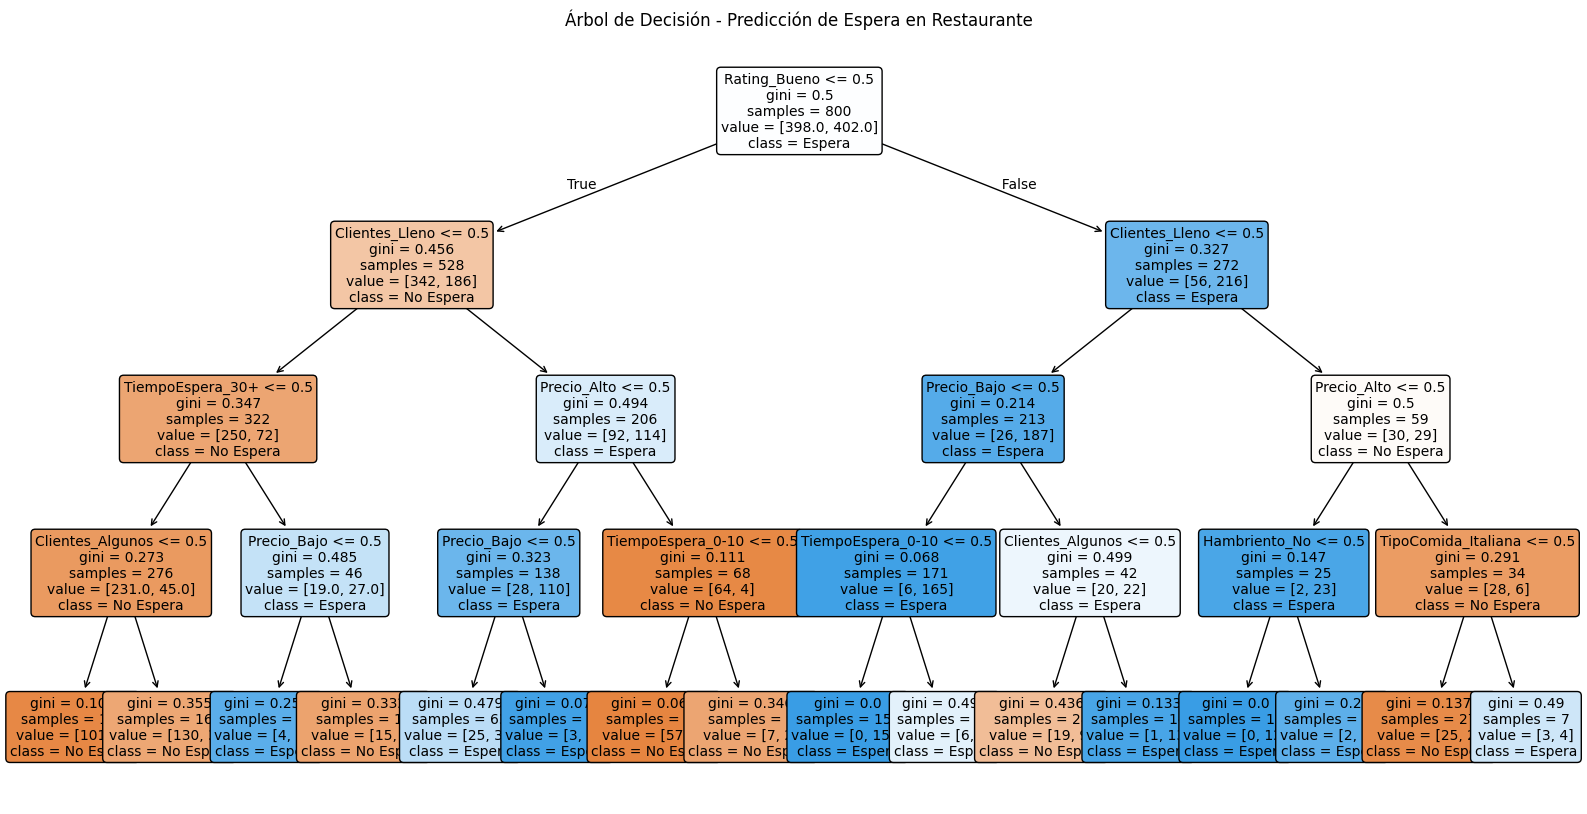

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Configuramos el tamaño de la figura
plt.figure(figsize=(20,10))

# Graficamos el árbol
plot_tree(
    modelo_arbol,
    feature_names=X_encoded.columns,
    class_names=["No Espera", "Espera"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Árbol de Decisión - Predicción de Espera en Restaurante")
plt.show()

#Explicacion
##Nodo Raiz
El árbol comienza evaluando la variable Rating_Bueno, lo que indica que la calificación del restaurante es el factor más determinante en la decisión del cliente.
- Si NO es bueno (<= 0.5) → el modelo tiende hacia No esperar
- Si SÍ es bueno (> 0.5) → el modelo tiende hacia Esperar

La calidad percibida del restaurante influye fuertemente en la decisión del cliente. Un buen rating aumenta significativamente la probabilidad de que el cliente esté dispuesto a esperar.

##Segunda decisión clave: cantidad de clientes
En ambos lados del árbol aparece: "Clientes_Lleno"

Esto confirma que el nivel de ocupación del restaurante es un factor crítico en la toma de decisión.

###🔸 CASO 1: Rating NO es bueno (lado izquierdo)

####Regla fuerte
- Si el rating es bueno
- Y el tiempo de espera es corto (0–10)

Resultado: Espera (muy alta probabilidad)

Los clientes están dispuestos a esperar cuando perciben alta calidad y el tiempo es razonable.

####Otra regla importante
- Si el precio es bajo

También favorece Espera

La combinación de calidad + bajo precio es altamente atractiva.

####Caso con hambre
- Si el cliente NO está hambriento

Igual puede esperar si el contexto es favorable

El hambre no es el factor principal; otros factores como calidad y precio pesan más.

###🔸 CASO 2: Rating SÍ es bueno (lado derecho)
####Regla fuerte
- Si el rating es bueno
- Y el tiempo de espera es corto (0–10)

Resultado: Espera (muy alta probabilidad)

Interpretación:

Los clientes están dispuestos a esperar cuando perciben alta calidad y el tiempo es razonable.

####Impureza Gini en los nodos

Se observa que:

- Nodos cercanos a hojas → Gini bajo (más puros)
- Algunos nodos → Gini cercano a 0.5

Interpretación:

Existen regiones donde el modelo no puede separar completamente las clases, lo cual está directamente relacionado con las combinaciones conflictivas detectadas previamente en el dataset.

##Interpretacion
El árbol de decisión permite identificar claramente los factores que influyen en la decisión del cliente. La variable más relevante es la calificación del restaurante (Rating), seguida por la cantidad de clientes y el precio.

Se observa que los clientes tienden a esperar cuando perciben alta calidad y condiciones favorables como bajo precio o tiempos de espera cortos. Por el contrario, una mala calificación combinada con tiempos largos o alta ocupación reduce significativamente la probabilidad de espera.

Además, la presencia de nodos con impureza intermedia refleja la existencia de combinaciones conflictivas en el dataset, lo que limita la capacidad del modelo para realizar separaciones perfectas.

##8.2 Visualización de la curva de aprendizaje
La curva de aprendizaje muestra cómo evoluciona el rendimiento del modelo a medida que aumenta la cantidad de datos de entrenamiento.

Permite detectar:

- Sobreajuste (overfitting)
- Subajuste (underfitting)
- Capacidad de generalización

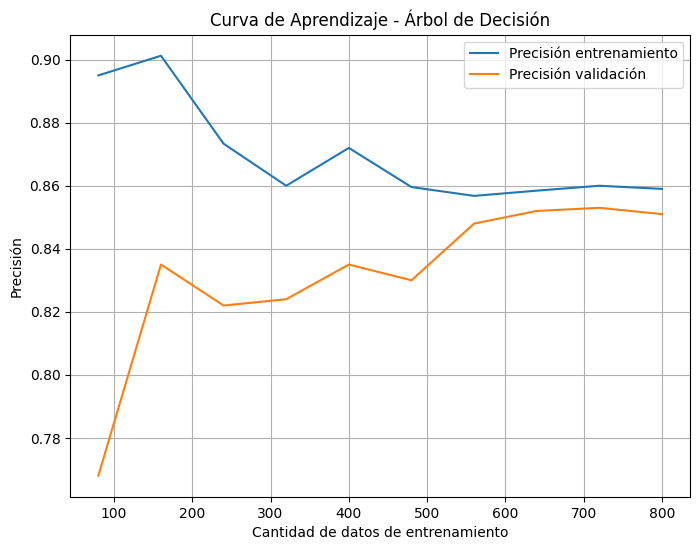

In [ ]:
from sklearn.model_selection import learning_curve
import numpy as np

# Calculamos la curva de aprendizaje
train_sizes, train_scores, test_scores = learning_curve(
    modelo_arbol,
    X_encoded,
    y,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10),
    random_state=42
)

# Promedios
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

# Gráfico
plt.figure(figsize=(8,6))
plt.plot(train_sizes, train_mean, label="Precisión entrenamiento")
plt.plot(train_sizes, test_mean, label="Precisión validación")

plt.xlabel("Cantidad de datos de entrenamiento")
plt.ylabel("Precisión")
plt.title("Curva de Aprendizaje - Árbol de Decisión")
plt.legend()
plt.grid()

plt.show()

#Descripción general

La curva de aprendizaje muestra cómo evoluciona la precisión del modelo a medida que aumenta la cantidad de datos de entrenamiento.

En el gráfico se comparan dos métricas:

- Precisión de entrenamiento (línea azul)
- Precisión de validación (línea naranja)

####Análisis del comportamiento del modelo
🔹 1. Precisión de entrenamiento

Se observa que la precisión de entrenamiento comienza en valores altos (~0.90) cuando se usan pocos datos, y luego disminuye ligeramente hasta estabilizarse alrededor de 0.86.
- Cuando el modelo entrena con pocos datos, memoriza fácilmente los patrones → alta precisión

🔹 2. Precisión de validación

La precisión de validación comienza en un valor bajo (~0.77) y aumenta progresivamente hasta estabilizarse cerca de 0.85.

🔹 3. Convergencia de las curvas

Ambas curvas tienden a acercarse conforme aumenta la cantidad de datos.
La diferencia entre entrenamiento (~0.86) y validación (~0.85) es pequeña.
Esto indica que el modelo tiene buena generalización y bajo sobreajuste

---

La curva de aprendizaje muestra que el modelo de árbol de decisión logra un buen equilibrio entre ajuste y generalización. A medida que aumenta la cantidad de datos, la precisión de validación mejora y se aproxima a la de entrenamiento, lo que indica que el modelo es capaz de aprender patrones representativos sin sobreajustarse.

Sin embargo, la precisión se estabiliza alrededor de 0.85, lo cual está directamente relacionado con la naturaleza del dataset, específicamente la presencia de combinaciones conflictivas que impiden una clasificación perfecta.

## 9. Interpretación Final (RESPONDER preguntas):

##9.1 ¿Qué atributo aparece en la raíz y por qué crees que fue seleccionado?
El atributo que aparece en la raíz del árbol de decisión es Rating_Bueno, es decir, si el restaurante tiene una buena calificación o no.

Este atributo fue seleccionado porque es el que mejor separa los datos en términos de la variable objetivo (Esperar), reduciendo en mayor medida la impureza de los datos según el criterio Gini.

Según el algoritmo de árboles de decisión:
En cada nodo, el modelo evalúa todas las posibles variables y selecciona aquella que produce la mayor reducción de impureza (Gini).

En este caso:

Rating_Bueno permite dividir los datos en dos grupos más “puros”, es decir, un grupo donde la mayoría espera y otro donde la mayoría no espera

##9.2 ¿Qué significa el valor de Gini en un nodo?
El valor de Gini en un nodo representa el grado de impureza o mezcla de clases dentro de ese nodo. Indica qué tan “heterogéneos” son los datos respecto a la variable objetivo (Esperar).

El valor de Gini varía entre:

- 0 → Nodo puro: Todos los datos pertenecen a una sola clase (por ejemplo, todos “Esperan” o todos “No esperan”).
- 0.5 → Máxima impureza (en problemas binarios):Los datos están completamente mezclados (50% “Sí” y 50% “No”).

En el modelo se observa nodos como:

- Gini = 0.0 → El nodo es completamente puro → decisión clara
- Gini ≈ 0.5 → El nodo está mezclado → alta incertidumbre

##9.3 ¿Qué evidencia en la curva de aprendizaje indica si el modelo generaliza adecuadamente?
La principal evidencia de que el modelo generaliza adecuadamente es que las curvas de precisión de entrenamiento y precisión de validación se acercan y se estabilizan en valores similares a medida que aumenta la cantidad de datos.

En la curva de aprendizaje se observa que:

- La precisión de entrenamiento se estabiliza alrededor de 0.86
- La precisión de validación se estabiliza cerca de 0.85
- La diferencia entre ambas curvas es muy pequeña

Esta cercanía entre ambas curvas indica que el modelo no está memorizando los datos de entrenamiento, sino que ha aprendido patrones que también funcionan bien en datos nuevos.

Relación con sobreajuste y subajuste
- No hay sobreajuste (overfitting): Porque la curva de entrenamiento no está muy por encima de la de validación
- No hay subajuste (underfitting): Porque ambas curvas alcanzan valores altos de precisión

##9.4 ¿Qué reglas puedes extraer del árbol?
A partir del árbol de decisión se pueden extraer reglas claras en forma de condiciones IF–THEN (Si–Entonces), que explican el comportamiento del modelo para predecir si un cliente esperará o no.

Regla 1 (la más importante)

- SI el Rating del restaurante es bueno, ENTONCES el cliente probablemente esperará.
- La calidad percibida es el factor más influyente en la decisión.

Regla 2

- SI el Rating NO es bueno Y el restaurante está lleno, ENTONCES el cliente NO esperará
- Mala calidad + alta ocupación → decisión negativa

Regla 3

- SI el Rating es bueno Y el Tiempo de Espera es corto (0–10 min), ENTONCES el cliente esperará
- Alta calidad + poco tiempo → alta probabilidad de espera

Regla 4

- SI el Precio es bajo, ENTONCES aumenta la probabilidad de que el cliente espere
- El precio actúa como incentivo, incluso si otras condiciones no son ideales

Regla 5

- SI el Tiempo de Espera es largo (30+) Y el Rating no es bueno, ENTONCES el cliente NO esperará
- Mucho tiempo + mala calidad → abandono casi seguro

Regla 6

- SI el restaurante NO está lleno Y hay condiciones moderadas (precio o tiempo aceptable), ENTONCES el cliente podría esperar
- Menor ocupación reduce la percepción de espera

Estas reglas se derivan directamente de los caminos desde la raíz hasta las hojas del árbol, donde cada nodo representa una condición sobre una variable.

Estas reglas podrían utilizarse en un sistema de recomendación o apoyo a la toma de decisiones en restaurantes.


##9.5 ¿Qué indica un nodo con alto valor de Gini sobre la confiabilidad de la predicción?

Un nodo con alto valor de Gini indica baja pureza en los datos y, por lo tanto, una menor confiabilidad en la predicción. En el contexto del laboratorio, esto se debe a la presencia de combinaciones conflictivas en el dataset, lo que introduce incertidumbre y limita la capacidad del modelo para tomar decisiones completamente precisas.

En problemas binarios (como este caso: Esperar = 0 o 1):

- Gini cercano a 0 → Nodo puro → Alta confiabilidad
- Gini cercano a 0.5 → Nodo mezclado → Baja confiabilidad

Por lo tanto: Mientras mayor sea el valor de Gini, mayor es la incertidumbre del modelo en ese nodo.

En el árbol se observaron nodos con valores de Gini relativamente altos (≈ 0.48 – 0.50).

Esto significa que:

- Los datos en ese nodo están casi divididos entre:
- Clientes que esperan
- Clientes que no esperan

Entonces: El modelo no puede tomar una decisión clara en esa región.